<a href="https://colab.research.google.com/github/sanchit-cmd/Loan-Eligibility-Classifier/blob/main/Loan_Eligibility_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vikasukani/loan-eligible-dataset")

print("Path to dataset files:", path)

100%|██████████| 12.5k/12.5k [00:00<00:00, 19.2MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/vikasukani/loan-eligible-dataset/versions/1


In [3]:
df = pd.read_csv("/root/.cache/kagglehub/datasets/vikasukani/loan-eligible-dataset/versions/1/loan-train.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [5]:
df = df.drop("Loan_ID", axis= 1)

In [6]:

for col in ['Gender', 'Married', 'Dependents', 'Self_Employed', 'Credit_History', 'Loan_Amount_Term']:
    df[col] = df[col].fillna(df[col].mode()[0])

df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].mean())


In [7]:

df['Dependents'] = df['Dependents'].astype(str).str.replace('+', '', regex=False)
df['Dependents'] = pd.to_numeric(df['Dependents'], errors='coerce')

binary_cols = {
    'Gender': {'Male': 1, 'Female': 0},
    'Married': {'Yes': 1, 'No': 0},
    'Education': {'Graduate': 1, 'Not Graduate': 0},
    'Self_Employed': {'Yes': 1, 'No': 0},
    'Loan_Status': {'Y': 1, 'N': 0}
}

for col, mapping in binary_cols.items():
    if col in df.columns:
        df[col] = df[col].map(mapping)


In [8]:

if 'Property_Area' in df.columns:
    df = pd.get_dummies(df, columns=['Property_Area'], drop_first=True, dtype=int)


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Gender                   614 non-null    int64  
 1   Married                  614 non-null    int64  
 2   Dependents               614 non-null    int64  
 3   Education                614 non-null    int64  
 4   Self_Employed            614 non-null    int64  
 5   ApplicantIncome          614 non-null    int64  
 6   CoapplicantIncome        614 non-null    float64
 7   LoanAmount               614 non-null    float64
 8   Loan_Amount_Term         614 non-null    float64
 9   Credit_History           614 non-null    float64
 10  Loan_Status              614 non-null    int64  
 11  Property_Area_Semiurban  614 non-null    int64  
 12  Property_Area_Urban      614 non-null    int64  
dtypes: float64(4), int64(9)
memory usage: 62.5 KB


In [11]:
X = df.drop('Loan_Status', axis=1)
y = df['Loan_Status']

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)


LogisticRegression()

In [13]:
lr_model.score(X_test, y_test)

0.7886178861788617

In [14]:
rf_model = RandomForestClassifier()
rf_model.fit(X_train, y_train)

RandomForestClassifier()

In [15]:
rf_model.score(X_test, y_test)

0.7723577235772358

In [16]:
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)

DecisionTreeClassifier()

In [17]:
dt_model.score(X_test, y_test)

0.7235772357723578

In [18]:
from sklearn.model_selection import GridSearchCV

# 1. Hyperparameter Tuning for Logistic Regression
lr_params = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

grid_lr = GridSearchCV(LogisticRegression(random_state=42), lr_params, cv=5, scoring='accuracy')
grid_lr.fit(X_train, y_train)

print("=== Logistic Regression Tuning ===")
print(f"Best Parameters: {grid_lr.best_params_}")
print(f"Best CV Score: {grid_lr.best_score_:.4f}")
print(f"Test Set Accuracy: {grid_lr.score(X_test, y_test):.4f}\n")

# 2. Hyperparameter Tuning for Random Forest
rf_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), rf_params, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X_train, y_train)

print("=== Random Forest Tuning ===")
print(f"Best Parameters: {grid_rf.best_params_}")
print(f"Best CV Score: {grid_rf.best_score_:.4f}")
print(f"Test Set Accuracy: {grid_rf.score(X_test, y_test):.4f}")

=== Logistic Regression Tuning ===
Best Parameters: {'C': 0.01, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV Score: 0.8166
Test Set Accuracy: 0.7886

=== Random Forest Tuning ===
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 50}
Best CV Score: 0.8126
Test Set Accuracy: 0.7886


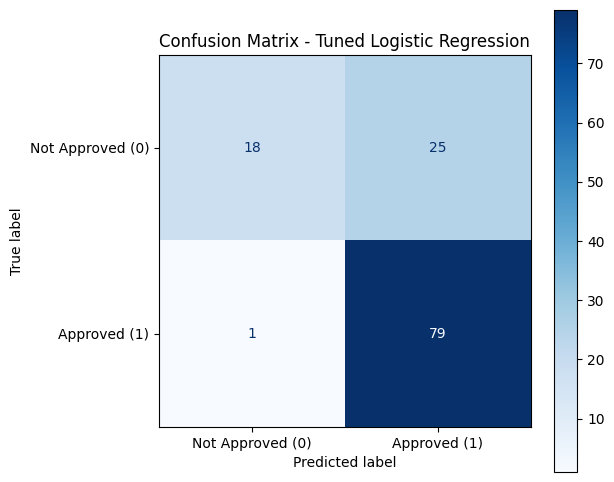

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get predictions from the best tuned Logistic Regression model
best_lr_model = grid_lr.best_estimator_
y_pred = best_lr_model.predict(X_test)

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Approved (0)', 'Approved (1)'])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix - Tuned Logistic Regression')
plt.show()

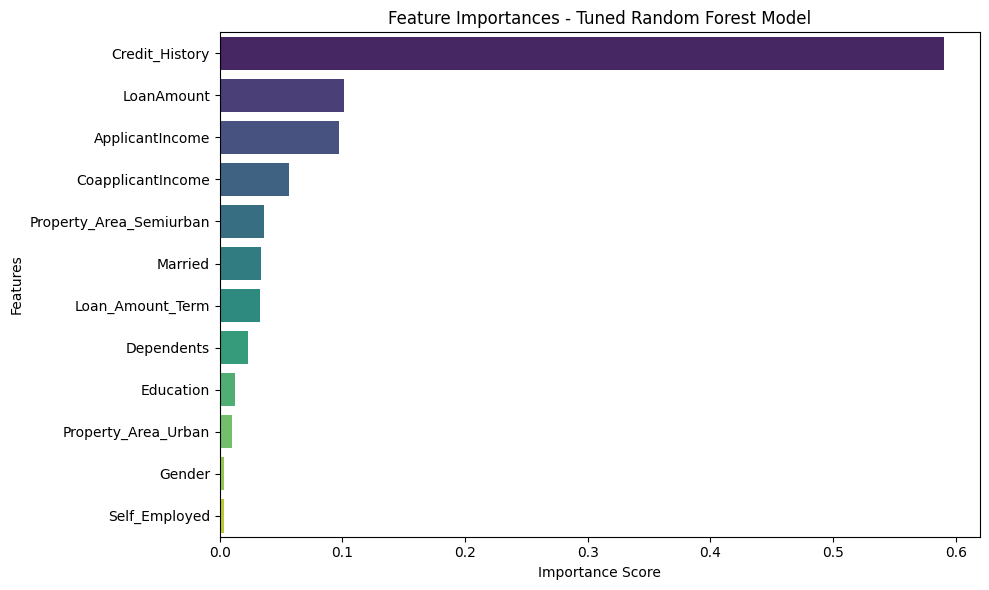

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get the feature names (excluding the target column)
feature_names = df.drop('Loan_Status', axis=1).columns

# Retrieve the best estimator from Random Forest tuning
best_rf_model = grid_rf.best_estimator_
importances = best_rf_model.feature_importances_

# Create a DataFrame for visualization
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis', hue='Feature', legend=False)
plt.title('Feature Importances - Tuned Random Forest Model')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import classification_report

# Get predictions from the best tuned Random Forest model
best_rf_model = grid_rf.best_estimator_
y_pred_rf = best_rf_model.predict(X_test)

# Generate and print the classification report
report = classification_report(y_test, y_pred_rf, target_names=['Not Approved (0)', 'Approved (1)'])
print("=== Classification Report - Tuned Random Forest ===")
print(report)

=== Classification Report - Tuned Random Forest ===
                  precision    recall  f1-score   support

Not Approved (0)       0.95      0.42      0.58        43
    Approved (1)       0.76      0.99      0.86        80

        accuracy                           0.79       123
       macro avg       0.85      0.70      0.72       123
    weighted avg       0.83      0.79      0.76       123



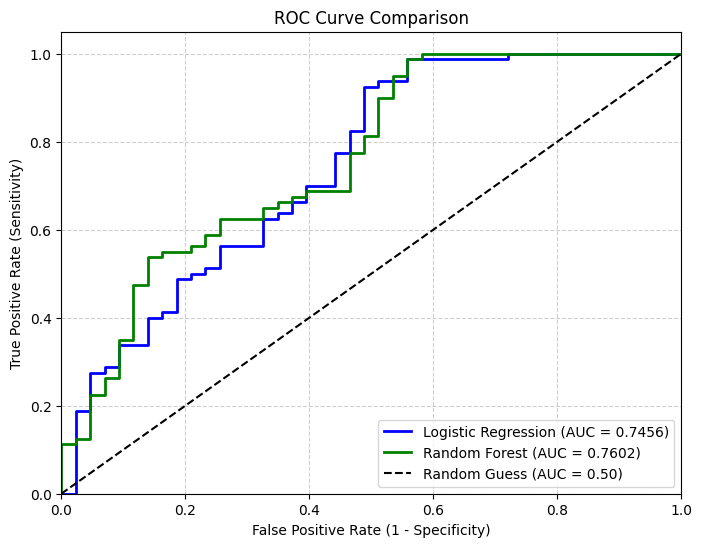

In [22]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get predicted probabilities for the positive class (class 1)
y_pred_proba_lr = best_lr_model.predict_proba(X_test)[:, 1]
y_pred_proba_rf = best_rf_model.predict_proba(X_test)[:, 1]

# Calculate ROC curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)

# Calculate AUC scores
auc_lr = roc_auc_score(y_test, y_pred_proba_lr)
auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

# Plot the ROC curves
plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.4f})', color='blue', lw=2)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.4f})', color='green', lw=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

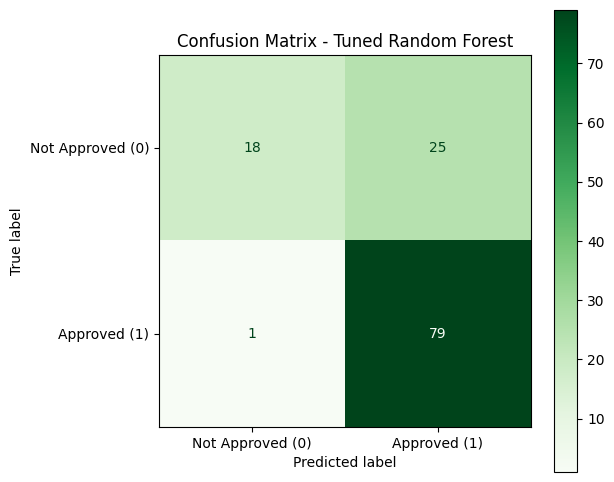

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compute the confusion matrix for the tuned Random Forest model
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Plot the confusion matrix
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Not Approved (0)', 'Approved (1)'])
fig, ax = plt.subplots(figsize=(6, 6))
disp_rf.plot(cmap='Greens', ax=ax)
plt.title('Confusion Matrix - Tuned Random Forest')
plt.show()

### Adjusting the Classification Threshold
We can adjust the probability threshold to be more selective about approving loans (e.g., requiring a **70%** probability score of approval instead of the default **50%**). This directly reduces false approvals.

=== Random Forest with Stricter Threshold (0.7) ===
                  precision    recall  f1-score   support

Not Approved (0)       0.72      0.49      0.58        43
    Approved (1)       0.77      0.90      0.83        80

        accuracy                           0.76       123
       macro avg       0.75      0.69      0.71       123
    weighted avg       0.75      0.76      0.74       123



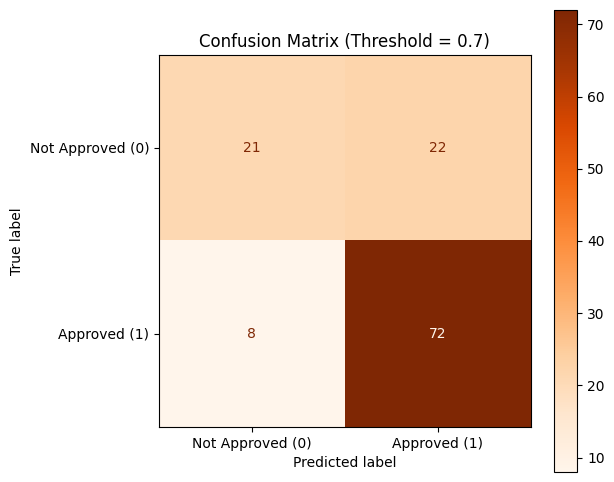

In [24]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Set a custom, stricter threshold for loan approval (e.g., 0.7 instead of 0.5)
custom_threshold = 0.7

# Generate predictions based on the new threshold
y_pred_rf_custom = (y_pred_proba_rf >= custom_threshold).astype(int)

# Print the updated classification report
print(f"=== Random Forest with Stricter Threshold ({custom_threshold}) ===")
print(classification_report(y_test, y_pred_rf_custom, target_names=['Not Approved (0)', 'Approved (1)']))

# Compute and plot the new confusion matrix
cm_rf_custom = confusion_matrix(y_test, y_pred_rf_custom)
disp_rf_custom = ConfusionMatrixDisplay(confusion_matrix=cm_rf_custom, display_labels=['Not Approved (0)', 'Approved (1)'])

fig, ax = plt.subplots(figsize=(6, 6))
disp_rf_custom.plot(cmap='Oranges', ax=ax)
plt.title(f'Confusion Matrix (Threshold = {custom_threshold})')
plt.show()

### Financial Trade-Off Analysis: 0.5 vs 0.7 Threshold
We will define some business parameters to translate the confusion matrix changes into financial terms:
* **Average Loan Amount:** Calculated dynamically from the test set.
* **Profit Margin on approved loans (Good Loans):** 15%
* **Loss Rate on defaulted loans (Bad Loans):** 50%

In [25]:
import pandas as pd

# Calculate the average loan amount in our test set (scaled back to original if needed)
# Since we fit a StandardScaler on the dataset, let's reverse-transform or use the original df's test indices.
# Let's approximate the average loan amount using the unscaled test set average:
test_indices = y_test.index
avg_loan_amount = df.loc[test_indices, 'LoanAmount'].mean() * 1000  # Multiplying by 1000 as loan amounts are typically in thousands

# Business Assumptions
profit_margin = 0.15      # 15% lifetime profit on a good loan
default_loss_rate = 0.50  # 50% write-off loss on a defaulted loan

# Profit/Loss per unit
revenue_per_good_loan = avg_loan_amount * profit_margin
loss_per_bad_loan = avg_loan_amount * default_loss_rate

# --- Baseline (0.5 Threshold) ---
# FP (False Approvals) = 25 | FN (False Rejections) = 1
fp_05 = 25
fn_05 = 1

# --- Stricter (0.7 Threshold) ---
# FP (False Approvals) = 22 | FN (False Rejections) = 8
fp_07 = 22
fn_07 = 8

# Changes
prevented_defaults = fp_05 - fp_07  # 3 bad loans saved
new_false_rejections = fn_07 - fn_05  # 7 good loans missed

# Financial impact
savings_from_prevented_defaults = prevented_defaults * loss_per_bad_loan
cost_of_false_rejections = new_false_rejections * revenue_per_good_loan
net_savings = savings_from_prevented_defaults - cost_of_false_rejections

# Print results
print(f"Average Loan Amount: ${avg_loan_amount:,.2f}")
print(f"Revenue per Good Loan (15%): ${revenue_per_good_loan:,.2f}")
print(f"Loss per Defaulted Loan (50%): ${loss_per_bad_loan:,.2f}\n")
print(f"=== Transitioning from 0.5 to 0.7 Threshold ===")
print(f"Savings from prevented defaults (3 saved): ${savings_from_prevented_defaults:,.2f}")
print(f"Cost of missed good loans (7 lost): ${cost_of_false_rejections:,.2f}")
print(f"Net Financial Benefit: ${net_savings:,.2f}")

Average Loan Amount: $137,491.65
Revenue per Good Loan (15%): $20,623.75
Loss per Defaulted Loan (50%): $68,745.83

=== Transitioning from 0.5 to 0.7 Threshold ===
Savings from prevented defaults (3 saved): $206,237.48
Cost of missed good loans (7 lost): $144,366.23
Net Financial Benefit: $61,871.24


### Visualizing Net Financial Benefit Across Different Thresholds
Let's evaluate thresholds from **0.5 to 0.9** (in steps of 0.05) to see which decision boundary maximizes our overall net financial returns.

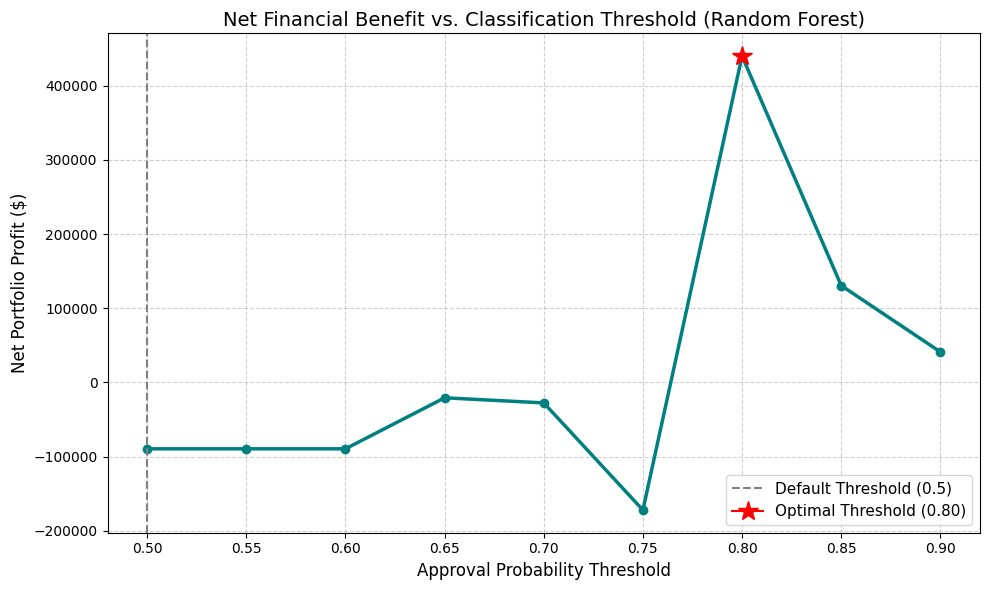

The financially optimal decision threshold is 0.80, yielding a net portfolio profit of $439,973.28 on the test set.


In [26]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Define the range of thresholds
thresholds = np.arange(0.5, 0.91, 0.05)

# Arrays to store metrics
net_benefits = []

# Baseline metrics at 0.5 threshold
# We will calculate total financial outcome at each threshold relative to our business defaults
# Financial outcome = (True Positives * Revenue) - (False Positives * Loss)
for th in thresholds:
    preds_custom = (y_pred_proba_rf >= th).astype(int)
    cm_custom = confusion_matrix(y_test, preds_custom)

    # Confusion matrix elements
    tn, fp, fn, tp = cm_custom.ravel()

    # Total net profit = (Successful approved loans * revenue) - (Bad loans approved * loss)
    total_profit = (tp * revenue_per_good_loan) - (fp * loss_per_bad_loan)
    net_benefits.append(total_profit)

# Plotting the threshold vs. Net Financial Outcome
plt.figure(figsize=(10, 6))
plt.plot(thresholds, net_benefits, marker='o', color='teal', linewidth=2.5)
plt.title('Net Financial Benefit vs. Classification Threshold (Random Forest)', fontsize=14)
plt.xlabel('Approval Probability Threshold', fontsize=12)
plt.ylabel('Net Portfolio Profit ($)', fontsize=12)
plt.axvline(x=0.5, color='gray', linestyle='--', label='Default Threshold (0.5)')

# Find and mark the optimal threshold
opt_idx = np.argmax(net_benefits)
opt_threshold = thresholds[opt_idx]
opt_benefit = net_benefits[opt_idx]
plt.plot(opt_threshold, opt_benefit, marker='*', color='red', markersize=15, label=f'Optimal Threshold ({opt_threshold:.2f})')

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

print(f"The financially optimal decision threshold is {opt_threshold:.2f}, yielding a net portfolio profit of ${opt_benefit:,.2f} on the test set.")

### Confusion Matrix at the Financially Optimal Threshold (0.80)
Let's plot the confusion matrix for the Random Forest model operating at the optimized **0.80 threshold** to see the distribution of correct and incorrect predictions.

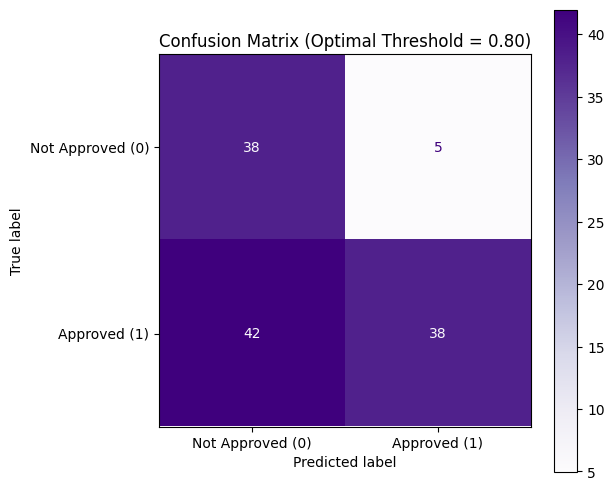

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate predictions using the optimal threshold of 0.80
opt_threshold = 0.80
y_pred_rf_opt = (y_pred_proba_rf >= opt_threshold).astype(int)

# Compute the confusion matrix
cm_rf_opt = confusion_matrix(y_test, y_pred_rf_opt)

# Plot the confusion matrix
disp_rf_opt = ConfusionMatrixDisplay(confusion_matrix=cm_rf_opt, display_labels=['Not Approved (0)', 'Approved (1)'])
fig, ax = plt.subplots(figsize=(6, 6))
disp_rf_opt.plot(cmap='Purples', ax=ax)
plt.title(f'Confusion Matrix (Optimal Threshold = {opt_threshold:.2f})')
plt.show()